### House Price Estimator

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import pandas as pd
data = pd.read_csv("datasets/california_housing_prices.csv")

In [4]:
data["median_house_value"].describe()

count     20640.000000
mean     206855.816909
std      115395.615874
min       14999.000000
25%      119600.000000
50%      179700.000000
75%      264725.000000
max      500001.000000
Name: median_house_value, dtype: float64

### EDA

In [5]:
from src import eda

eda.inspect(data)

Shape: (20640, 10)

Null value count:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Duplicate rows:
0



In [6]:
from src import data_split as ds

X_train, X_valid, X_test, y_train, y_valid, y_test = ds.split(data)

bedroom_median = X_train["total_bedrooms"].median()

X_train["total_bedrooms"] = X_train["total_bedrooms"].fillna(bedroom_median)
X_valid["total_bedrooms"] = X_valid["total_bedrooms"].fillna(bedroom_median)
X_test["total_bedrooms"] = X_test["total_bedrooms"].fillna(bedroom_median)

In [7]:
X_valid.isna().sum()

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
ocean_proximity       0
dtype: int64

In [8]:
from src import string_encoder as se

X_train_encoded, X_valid_encoded, X_test_encoded = se.encode_string(X_train, X_valid, X_test)

In [9]:
X_train_encoded

,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
14196,0.0,0.0,0.0,0.0,1.0,-117.03,32.71,33.0,3126.0,627.0,2300.0,623.0,3.2596
8267,0.0,0.0,0.0,0.0,1.0,-118.16,33.77,49.0,3382.0,787.0,1314.0,756.0,3.8125
17445,0.0,0.0,0.0,0.0,1.0,-120.48,34.66,4.0,1897.0,331.0,915.0,336.0,4.1563
14265,0.0,0.0,0.0,0.0,1.0,-117.11,32.69,36.0,1421.0,367.0,1418.0,355.0,1.9425
2271,0.0,1.0,0.0,0.0,0.0,-119.80,36.78,43.0,2382.0,431.0,874.0,380.0,3.5542
...,...,...,...,...,...,...,...,...,...,...,...,...,...
11284,1.0,0.0,0.0,0.0,0.0,-117.96,33.78,35.0,1330.0,201.0,658.0,217.0,6.3700
11964,0.0,1.0,0.0,0.0,0.0,-117.43,34.02,33.0,3084.0,570.0,1753.0,449.0,3.0500
5390,1.0,0.0,0.0,0.0,0.0,-118.38,34.03,36.0,2101.0,569.0,1756.0,527.0,2.9344
860,1.0,0.0,0.0,0.0,0.0,-121.96,37.58,15.0,3575.0,597.0,1777.0,559.0,5.7192


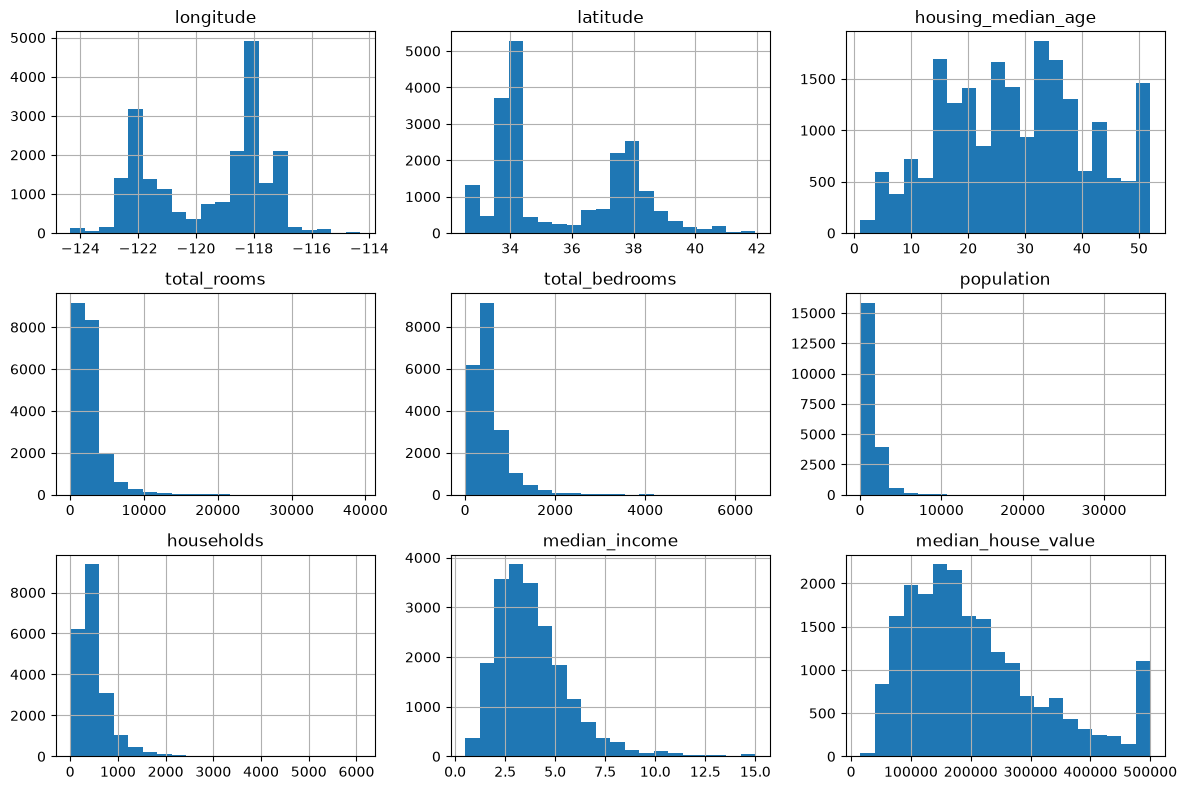

In [10]:
from matplotlib import pyplot as plt
data.hist(
    bins=20,
    figsize=(12, 8)
)

plt.tight_layout()
plt.show()

In [11]:
from src import outlier_detection as od

flags = od.detect_out(X_train_encoded)

flags.sum()

<1H OCEAN                0
INLAND                   0
ISLAND                   4
NEAR BAY              1854
NEAR OCEAN            2086
longitude                0
latitude                 0
housing_median_age       0
total_rooms           1046
total_bedrooms        1041
population             955
households             977
median_income          529
dtype: int64

In [12]:
check = X_train_encoded[["population", "households", "total_rooms", "total_bedrooms"]].copy()

check["people_per_household"] = check["population"] / check["households"]
check["rooms_per_household"] = check["total_rooms"] / check["households"]

check.sort_values("people_per_household", ascending=False).head()

,population,households,total_rooms,total_bedrooms,people_per_household,rooms_per_household
19006,7460.0,6.0,19.0,5.0,1243.333333,3.166667
3364,4198.0,7.0,36.0,8.0,599.714286,5.142857
16669,6532.0,13.0,118.0,17.0,502.461538,9.076923
13034,6675.0,29.0,240.0,44.0,230.172414,8.275862
16420,1542.0,30.0,161.0,27.0,51.400000,5.366667


In [13]:
threshold = 10

above_threshold = check["people_per_household"] > threshold

print(f"Rows above threshold: {above_threshold.sum()}")

check.loc[above_threshold, ["households", "people_per_household"]].sort_values("people_per_household", ascending=False)

Rows above threshold: 35


,households,people_per_household
19006,6.0,1243.333333
3364,7.0,599.714286
16669,13.0,502.461538
13034,29.0,230.172414
16420,30.0,51.400000
8874,28.0,41.214286
13366,85.0,33.952941
5986,126.0,21.333333
20352,16.0,19.312500
14756,275.0,18.821818


<Axes: xlabel='longitude', ylabel='latitude'>

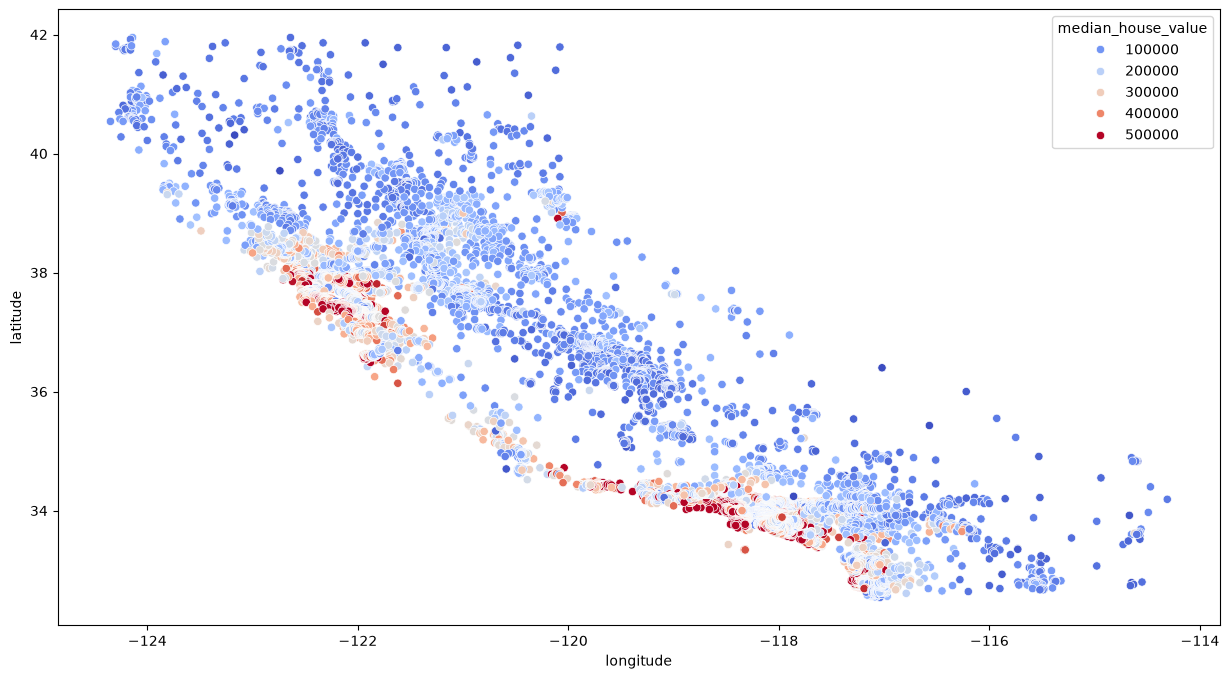

In [14]:
import seaborn as sns
plt.figure(figsize=(15,8))
sns.scatterplot(x="longitude", y="latitude", data=data, hue="median_house_value", palette="coolwarm")

### Feature Engineering

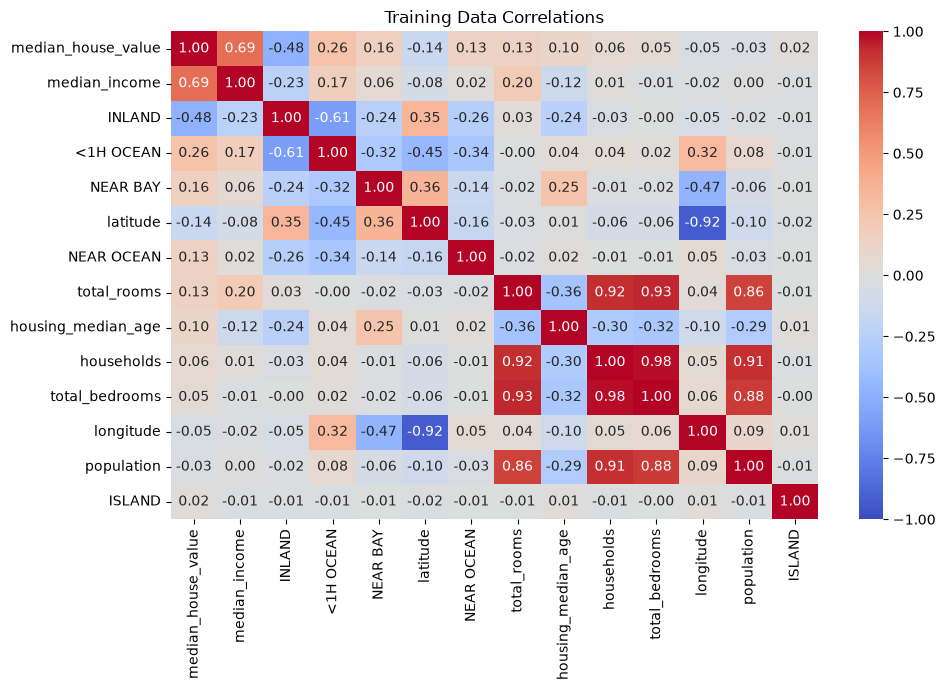

In [15]:
import seaborn as sns

train_data = X_train_encoded.join(y_train)

correlation = train_data.corr(numeric_only=True)

order = (
    correlation["median_house_value"]
    .abs()
    .sort_values(ascending=False)
    .index
)

correlation = correlation.loc[order, order]

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Training Data Correlations")
plt.tight_layout()
plt.show()

In [16]:
from src import feat_metrics as fm

feat_imp = fm.feat_analyse(X_train_encoded, y_train, X_valid_encoded, y_valid)

feat_imp

,dropped,MAE,RMSE,R2
10,total_bedrooms,50702.290020,69969.499410,0.628200
9,total_rooms,50871.647625,70274.350868,0.624953
3,ISLAND,50861.427822,70503.769399,0.622501
5,NEAR OCEAN,50861.427822,70503.769399,0.622501
4,NEAR BAY,50861.427822,70503.769399,0.622501
0,None,50861.427822,70503.769399,0.622501
2,INLAND,50861.427822,70503.769399,0.622501
1,<1H OCEAN,50861.427822,70503.769399,0.622501
8,housing_median_age,50886.966102,70830.522406,0.618993
12,households,51133.676673,71115.864449,0.615918


In [17]:
# list of dropped features
dropped_feats = []

In [18]:
from src import feat_engg as fe

# add features
X_train_fe = fe.add_features_v1(X_train_encoded)
X_valid_fe = fe.add_features_v1(X_valid_encoded)
X_test_fe = fe.add_features_v1(X_test_encoded)

In [19]:
# modify features
columns = ["total_bedrooms"] # drop columns

X_train_fe = X_train_fe.drop(columns=columns)
X_valid_fe = X_valid_fe.drop(columns=columns) 
X_test_fe = X_test_fe.drop(columns=columns) 

In [20]:
dropped_feats.append("total_bedrooms")

In [21]:
feat_imp = fm.feat_analyse(X_train_fe, y_train, X_valid_fe, y_valid)

feat_imp

,dropped,MAE,RMSE,R2
14,bedrooms_per_room,50578.205430,69750.492665,0.630524
9,total_rooms,50760.128596,73558.337632,0.589082
13,rooms_per_household,51110.119688,74007.763876,0.584045
8,housing_median_age,50971.946672,74062.216444,0.583433
3,ISLAND,50909.937704,74079.406824,0.583240
0,None,50909.937704,74079.406824,0.583240
2,INLAND,50909.937704,74079.406824,0.583240
5,NEAR OCEAN,50909.937704,74079.406824,0.583240
4,NEAR BAY,50909.937704,74079.406824,0.583240
1,<1H OCEAN,50909.937704,74079.406824,0.583240


In [22]:
columns = ["bedrooms_per_room"] # drop columns

X_train_fe = X_train_fe.drop(columns=columns)
X_valid_fe = X_valid_fe.drop(columns=columns) 
X_test_fe = X_test_fe.drop(columns=columns) 

In [23]:
dropped_feats.append("bedrooms_per_room")

In [24]:
feat_imp = fm.feat_analyse(X_train_fe, y_train, X_valid_fe, y_valid)

feat_imp

,dropped,MAE,RMSE,R2
3,ISLAND,50578.205430,69750.492665,0.630524
5,NEAR OCEAN,50578.205430,69750.492665,0.630524
4,NEAR BAY,50578.205430,69750.492665,0.630524
0,None,50578.205430,69750.492665,0.630524
1,<1H OCEAN,50578.205430,69750.492665,0.630524
2,INLAND,50578.205430,69750.492665,0.630524
14,people_per_household,50575.129846,69756.497529,0.630461
9,total_rooms,50650.089144,69763.560145,0.630386
13,rooms_per_household,50706.363526,69962.205651,0.628278
8,housing_median_age,50744.364225,70240.961259,0.625310


In [25]:
dropped_feats

['total_bedrooms', 'bedrooms_per_room']

In [26]:
# add features v2
X_train_fe = fe.add_features_v2(X_train_fe, X_train_encoded)
X_valid_fe = fe.add_features_v2(X_valid_fe, X_valid_encoded)
X_test_fe = fe.add_features_v2(X_test_fe, X_test_encoded)

In [27]:
X_train_fe

,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN,longitude,latitude,housing_median_age,total_rooms,population,households,median_income,rooms_per_household,people_per_household,bedrooms_per_household,rooms_per_person,income_squared
14196,0.0,0.0,0.0,0.0,1.0,-117.03,32.71,33.0,3126.0,2300.0,623.0,3.2596,5.017657,3.691814,1.006421,1.359130,10.624992
8267,0.0,0.0,0.0,0.0,1.0,-118.16,33.77,49.0,3382.0,1314.0,756.0,3.8125,4.473545,1.738095,1.041005,2.573820,14.535156
17445,0.0,0.0,0.0,0.0,1.0,-120.48,34.66,4.0,1897.0,915.0,336.0,4.1563,5.645833,2.723214,0.985119,2.073224,17.274830
14265,0.0,0.0,0.0,0.0,1.0,-117.11,32.69,36.0,1421.0,1418.0,355.0,1.9425,4.002817,3.994366,1.033803,1.002116,3.773306
2271,0.0,1.0,0.0,0.0,0.0,-119.80,36.78,43.0,2382.0,874.0,380.0,3.5542,6.268421,2.300000,1.134211,2.725400,12.632338
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11284,1.0,0.0,0.0,0.0,0.0,-117.96,33.78,35.0,1330.0,658.0,217.0,6.3700,6.129032,3.032258,0.926267,2.021277,40.576900
11964,0.0,1.0,0.0,0.0,0.0,-117.43,34.02,33.0,3084.0,1753.0,449.0,3.0500,6.868597,3.904232,1.269488,1.759270,9.302500
5390,1.0,0.0,0.0,0.0,0.0,-118.38,34.03,36.0,2101.0,1756.0,527.0,2.9344,3.986717,3.332068,1.079696,1.196469,8.610703
860,1.0,0.0,0.0,0.0,0.0,-121.96,37.58,15.0,3575.0,1777.0,559.0,5.7192,6.395349,3.178891,1.067979,2.011818,32.709249


In [28]:
feat_imp = fm.feat_analyse(X_train_fe, y_train, X_valid_fe, y_valid)

feat_imp

,dropped,MAE,RMSE,R2
15,bedrooms_per_household,49314.256507,68083.550174,0.647973
13,rooms_per_household,50206.829183,68908.469574,0.639391
17,income_squared,49507.940948,70477.118097,0.622786
10,population,49714.123154,71213.924967,0.614858
8,housing_median_age,49937.406305,71243.433079,0.614538
4,NEAR BAY,49942.154539,71889.452937,0.607516
5,NEAR OCEAN,49942.154539,71889.452937,0.607516
3,ISLAND,49942.154539,71889.452937,0.607516
2,INLAND,49942.154539,71889.452937,0.607516
0,None,49942.154539,71889.452937,0.607516


In [29]:
columns = ["bedrooms_per_household"]

X_train_fe, X_valid_fe, X_test_fe = fe.drop_features(columns, X_train_fe, X_valid_fe, X_test_fe)

In [30]:
X_train_fe

,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN,longitude,latitude,housing_median_age,total_rooms,population,households,median_income,rooms_per_household,people_per_household,rooms_per_person,income_squared
14196,0.0,0.0,0.0,0.0,1.0,-117.03,32.71,33.0,3126.0,2300.0,623.0,3.2596,5.017657,3.691814,1.359130,10.624992
8267,0.0,0.0,0.0,0.0,1.0,-118.16,33.77,49.0,3382.0,1314.0,756.0,3.8125,4.473545,1.738095,2.573820,14.535156
17445,0.0,0.0,0.0,0.0,1.0,-120.48,34.66,4.0,1897.0,915.0,336.0,4.1563,5.645833,2.723214,2.073224,17.274830
14265,0.0,0.0,0.0,0.0,1.0,-117.11,32.69,36.0,1421.0,1418.0,355.0,1.9425,4.002817,3.994366,1.002116,3.773306
2271,0.0,1.0,0.0,0.0,0.0,-119.80,36.78,43.0,2382.0,874.0,380.0,3.5542,6.268421,2.300000,2.725400,12.632338
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11284,1.0,0.0,0.0,0.0,0.0,-117.96,33.78,35.0,1330.0,658.0,217.0,6.3700,6.129032,3.032258,2.021277,40.576900
11964,0.0,1.0,0.0,0.0,0.0,-117.43,34.02,33.0,3084.0,1753.0,449.0,3.0500,6.868597,3.904232,1.759270,9.302500
5390,1.0,0.0,0.0,0.0,0.0,-118.38,34.03,36.0,2101.0,1756.0,527.0,2.9344,3.986717,3.332068,1.196469,8.610703
860,1.0,0.0,0.0,0.0,0.0,-121.96,37.58,15.0,3575.0,1777.0,559.0,5.7192,6.395349,3.178891,2.011818,32.709249


In [31]:
feat_imp = fm.feat_analyse(X_train_fe, y_train, X_valid_fe, y_valid)

feat_imp

,dropped,MAE,RMSE,R2
3,ISLAND,49314.256507,68083.550174,0.647973
5,NEAR OCEAN,49314.256507,68083.550174,0.647973
2,INLAND,49314.256507,68083.550174,0.647973
4,NEAR BAY,49314.256507,68083.550174,0.647973
0,None,49314.256507,68083.550174,0.647973
1,<1H OCEAN,49314.256507,68083.550174,0.647973
14,people_per_household,49311.648019,68087.772764,0.647929
9,total_rooms,49338.945358,68116.632403,0.647631
16,income_squared,49119.040653,68126.598684,0.647528
10,population,49223.844066,68267.931065,0.646064


### Training

### Linear Regressor

In [32]:
# Linear Regression
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(X_train_fe, y_train) 

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](16,)","[-19664.96,-56324.51,121717.16,..., 43.76, 32901.62, -644.86]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](16,)","['<1H OCEAN','INLAND','ISLAND',...,'people_per_household', 'rooms_per_person','income_squared']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-2.307e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,16
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(15)


In [33]:
y_pred_lr = lin_reg.predict(X_valid_fe)

In [34]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

print(f"Validation MAE: {mean_absolute_error(y_valid, y_pred_lr):.2f}")    
print(f"Validation RMSE: {root_mean_squared_error(y_valid, y_pred_lr):.2f}")
print(f"Validation R²: {lin_reg.score(X_valid_fe, y_valid)}")

Validation MAE: 49314.26
Validation RMSE: 68083.55
Validation R²: 0.6479730714855911


### Random Forest Regressor

In [35]:
# Random Forest Regressor
from sklearn.ensemble import RandomForestRegressor

forest = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

# forest.fit(X_train_encoded, y_train) # training on original data
forest.fit(X_train_fe, y_train) # training on original data

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [36]:
# y_pred_rf = forest.predict(X_valid_encoded)
y_pred_rf = forest.predict(X_valid_fe)

In [37]:
print(f"Validation MAE: {mean_absolute_error(y_valid, y_pred_rf)}")
print(f"Validation RMSE: {root_mean_squared_error(y_valid, y_pred_rf)}")
# print(f"Validation R²: {forest.score(X_valid_encoded, y_valid)}")
print(f"Validation R²: {forest.score(X_valid_fe, y_valid)}")
print("Training R²:", forest.score(X_train_fe, y_train))

Validation MAE: 35153.23877567118
Validation RMSE: 53448.573641784154
Validation R²: 0.7830479596983322
Training R²: 0.8725336391138234


In [38]:
# dataset for forest

X_train_mod = fe.add_features_v1(X_train_encoded)
X_train_mod = fe.add_features_v2(X_train_mod, X_train_encoded)

X_valid_mod = fe.add_features_v1(X_valid_encoded)
X_valid_mod = fe.add_features_v2(X_valid_mod, X_valid_encoded)

X_test_mod = fe.add_features_v1(X_test_encoded)
X_test_mod = fe.add_features_v2(X_test_mod, X_test_encoded)

In [39]:
X_test_mod

,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,rooms_per_household,bedrooms_per_room,people_per_household,bedrooms_per_household,rooms_per_person,income_squared
3752,1.0,0.0,0.0,0.0,0.0,-118.38,34.17,33.0,1588.0,454.0,739.0,392.0,2.8208,4.051020,0.285894,1.885204,1.158163,2.148850,7.956913
16705,1.0,0.0,0.0,0.0,0.0,-120.52,35.06,11.0,1317.0,234.0,655.0,243.0,4.3611,5.419753,0.177677,2.695473,0.962963,2.010687,19.019193
2915,0.0,1.0,0.0,0.0,0.0,-119.06,35.36,9.0,1228.0,234.0,409.0,212.0,4.3482,5.792453,0.190554,1.929245,1.103774,3.002445,18.906843
9728,1.0,0.0,0.0,0.0,0.0,-121.65,36.85,20.0,2606.0,424.0,1361.0,426.0,4.5787,6.117371,0.162701,3.194836,0.995305,1.914769,20.964494
3352,0.0,1.0,0.0,0.0,0.0,-120.96,40.28,19.0,683.0,139.0,302.0,111.0,2.5000,6.153153,0.203514,2.720721,1.252252,2.261589,6.250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20506,1.0,0.0,0.0,0.0,0.0,-118.73,34.29,8.0,4983.0,754.0,2510.0,725.0,6.9454,6.873103,0.151314,3.462069,1.040000,1.985259,48.238581
16403,0.0,1.0,0.0,0.0,0.0,-121.19,38.04,35.0,703.0,117.0,290.0,107.0,3.2250,6.570093,0.166430,2.710280,1.093458,2.424138,10.400625
5345,1.0,0.0,0.0,0.0,0.0,-118.42,34.04,46.0,1508.0,276.0,639.0,273.0,4.9250,5.523810,0.183024,2.340659,1.010989,2.359937,24.255625
16787,0.0,0.0,0.0,0.0,1.0,-122.47,37.66,18.0,4172.0,806.0,3226.0,790.0,5.7535,5.281013,0.193193,4.083544,1.020253,1.293242,33.102762


In [40]:
dropped_feats_forest = []

In [41]:
import importlib
importlib.reload(fm)

<module 'src.feat_metrics' from 'c:\\Users\\natha\\ip\\ml\\house_price_estimator\\src\\feat_metrics.py'>

In [42]:
feat_imp_forest = fm.feat_analyse_forest(X_train_mod, y_train, X_valid_mod, y_valid)

feat_imp_forest

,dropped,MAE,RMSE,R2
15,bedrooms_per_room,35372.167638,53649.858320,0.781411
10,total_bedrooms,35483.534130,53877.215755,0.779554
3,ISLAND,35565.788261,54004.646748,0.778510
0,None,35560.138456,54016.636690,0.778412
9,total_rooms,35559.535229,54029.456546,0.778307
17,bedrooms_per_household,35534.775750,54039.656610,0.778223
19,income_squared,35592.408108,54048.869854,0.778147
13,median_income,35588.519370,54070.095479,0.777973
14,rooms_per_household,35586.612265,54071.693217,0.777960
4,NEAR BAY,35597.403438,54073.591214,0.777944


In [43]:
columns = ["bedrooms_per_room"]
X_train_mod, X_valid_mod, X_test_mod = fe.drop_features(columns, X_train_mod, X_valid_mod, X_test_mod)

In [44]:
dropped_feats_forest.append("bedrooms_per_room")

In [45]:
dropped_feats_forest

['bedrooms_per_room']

In [46]:
feat_imp_forest = fm.feat_analyse_forest(X_train_mod, y_train, X_valid_mod, y_valid)

feat_imp_forest

,dropped,MAE,RMSE,R2
14,rooms_per_household,35201.493273,53488.189368,0.782726
18,income_squared,35322.788613,53532.703062,0.782364
10,total_bedrooms,35336.750629,53591.824247,0.781883
16,bedrooms_per_household,35258.697713,53606.356723,0.781765
4,NEAR BAY,35390.276711,53625.132378,0.781612
1,<1H OCEAN,35368.309722,53636.645141,0.781518
3,ISLAND,35393.144362,53649.519325,0.781414
0,None,35372.167638,53649.858320,0.781411
13,median_income,35400.194465,53664.133325,0.781294
9,total_rooms,35418.504643,53684.677292,0.781127


In [180]:
from src.tuning import tune_forest

X_train_raw = data.loc[y_train.index].drop(columns="median_house_value")

search = tune_forest(
    X_train_raw,
    y_train,
    # selected_columns=forest.feature_names_in_.tolist(),
    selected_columns=X_train_mod.columns.tolist()
)

print("Best parameters:", search.best_params_)
print("Best average CV RMSE:", -search.best_score_)

best_model = search.best_estimator_

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best parameters: {'forest__max_depth': 20, 'forest__max_features': 1.0, 'forest__min_samples_leaf': 1}
Best average CV RMSE: 50828.55996649656


In [47]:
columns = ["rooms_per_household"]
X_train_mod, X_valid_mod, X_test_mod = fe.drop_features(columns, X_train_mod, X_valid_mod, X_test_mod)
dropped_feats_forest.append("rooms_per_household")

In [48]:
feat_imp_forest = fm.feat_analyse_forest(X_train_mod, y_train, X_valid_mod, y_valid)

feat_imp_forest

,dropped,MAE,RMSE,R2
10,total_bedrooms,35106.923637,53336.144587,0.783960
15,bedrooms_per_household,35028.207324,53339.359141,0.783934
9,total_rooms,35183.617403,53441.308491,0.783107
5,NEAR OCEAN,35225.266706,53459.514061,0.782959
13,median_income,35205.043810,53463.381866,0.782928
11,population,35167.185265,53472.387660,0.782855
3,ISLAND,35193.041061,53487.663989,0.782731
0,None,35201.493273,53488.189368,0.782726
4,NEAR BAY,35206.241566,53493.587210,0.782682
1,<1H OCEAN,35197.653721,53510.261468,0.782547


In [49]:
columns = ["total_bedrooms"]
X_train_mod, X_valid_mod, X_test_mod = fe.drop_features(columns, X_train_mod, X_valid_mod, X_test_mod)
dropped_feats_forest.append("total_bedrooms")

In [50]:
feat_imp_forest = fm.feat_analyse_forest(X_train_mod, y_train, X_valid_mod, y_valid)

feat_imp_forest

,dropped,MAE,RMSE,R2
14,bedrooms_per_household,34896.426493,53165.724551,0.785338
11,households,34943.357039,53175.213232,0.785261
12,median_income,35072.485181,53328.380456,0.784023
3,ISLAND,35082.211011,53334.878691,0.783970
0,None,35106.923637,53336.144587,0.783960
16,income_squared,35098.292584,53363.184442,0.783741
9,total_rooms,35121.781785,53392.288511,0.783505
10,population,35110.576957,53411.255834,0.783351
1,<1H OCEAN,35082.431435,53414.001000,0.783329
4,NEAR BAY,35136.116471,53443.039800,0.783093


In [ ]:
columns = ["bedrooms_per_household"]
X_train_mod, X_valid_mod, X_test_mod = fe.drop_features(columns, X_train_mod, X_valid_mod, X_test_mod)
dropped_feats_forest.append("bedrooms_per_household")

In [52]:
feat_imp_forest = fm.feat_analyse_forest(X_train_mod, y_train, X_valid_mod, y_valid)

feat_imp_forest

,dropped,MAE,RMSE,R2
11,households,34790.172545,53099.923035,0.785869
5,NEAR OCEAN,34902.182683,53165.466036,0.785340
0,None,34896.426493,53165.724551,0.785338
3,ISLAND,34879.915627,53190.841657,0.785135
15,income_squared,34906.673471,53194.979555,0.785102
10,population,34880.121802,53215.166373,0.784939
4,NEAR BAY,34883.170718,53221.624855,0.784886
9,total_rooms,34911.007666,53222.864481,0.784876
12,median_income,34933.277939,53228.891474,0.784828
1,<1H OCEAN,34920.776242,53265.209955,0.784534


In [ ]:
columns = ["households"]
X_train_mod, X_valid_mod, X_test_mod = fe.drop_features(columns, X_train_mod, X_valid_mod, X_test_mod)
dropped_feats_forest.append("households")

In [54]:
feat_imp_forest = fm.feat_analyse_forest(X_train_mod, y_train, X_valid_mod, y_valid)

feat_imp_forest

,dropped,MAE,RMSE,R2
3,ISLAND,34719.065689,52960.138439,0.786995
14,income_squared,34740.226024,53032.400323,0.786413
11,median_income,34743.061443,53033.217845,0.786407
4,NEAR BAY,34756.434997,53039.458748,0.786357
9,total_rooms,34754.541900,53070.201753,0.786109
10,population,34766.337493,53091.545409,0.785937
5,NEAR OCEAN,34824.850702,53098.067495,0.785884
0,None,34790.172545,53099.923035,0.785869
1,<1H OCEAN,34803.820193,53145.255609,0.785503
13,rooms_per_person,35017.930957,53671.466292,0.781235


In [55]:
columns = ["ISLAND"]
X_train_mod, X_valid_mod, X_test_mod = fe.drop_features(columns, X_train_mod, X_valid_mod, X_test_mod)
dropped_feats_forest.append("ISLAND")

In [56]:
feat_imp_forest = fm.feat_analyse_forest(X_train_mod, y_train, X_valid_mod, y_valid)

feat_imp_forest

,dropped,MAE,RMSE,R2
0,None,34719.065689,52960.138439,0.786995
10,median_income,34749.669744,52987.049968,0.786779
8,total_rooms,34739.865343,53021.298345,0.786503
3,NEAR BAY,34779.332912,53034.848533,0.786394
9,population,34766.239100,53050.058283,0.786271
13,income_squared,34792.742509,53051.414104,0.786260
4,NEAR OCEAN,34773.094888,53061.228870,0.786181
1,<1H OCEAN,34797.686607,53107.413172,0.785809
12,rooms_per_person,35012.610989,53682.386270,0.781146
11,people_per_household,35337.074037,53814.472786,0.780067


In [ ]:
forest.fit(X_train_mod, y_train)    

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [58]:
y_pred_rf = forest.predict(X_valid_mod)

In [59]:
print(f"Validation MAE: {mean_absolute_error(y_valid, y_pred_rf)}")
print(f"Validation RMSE: {root_mean_squared_error(y_valid, y_pred_rf)}")
print(f"Validation R²: {forest.score(X_valid_mod, y_valid)}")
print("Training R²:", forest.score(X_train_mod, y_train))

Validation MAE: 34719.065689204406
Validation RMSE: 52960.13843930057
Validation R²: 0.7869950370969264
Training R²: 0.872085804648882


### Cross Validation again

In [60]:
from src.tuning import tune_forest

X_train_raw = data.loc[y_train.index].drop(columns="median_house_value")

search = tune_forest(
    X_train_raw,
    y_train,
    selected_columns=X_train_mod.columns.tolist()
)

print("Best parameters:", search.best_params_)
print("Best average CV RMSE:", -search.best_score_)

best_model = search.best_estimator_

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best parameters: {'forest__max_depth': None, 'forest__max_features': 1.0, 'forest__min_samples_leaf': 1}
Best average CV RMSE: 50235.60814591028


In [61]:
results = pd.DataFrame(search.cv_results_)

results["CV_MAE"] = -results["mean_test_MAE"]
results["CV_RMSE"] = -results["mean_test_RMSE"]

display(
    results[
        ["params", "CV_MAE", "CV_RMSE", "mean_test_R2", "std_test_R2"]
    ].sort_values("CV_RMSE")
)

,params,CV_MAE,CV_RMSE,mean_test_R2,std_test_R2
10,"{'forest__max_depth': None, 'forest__max_featu...",32796.421766,50235.608146,0.811138,0.004936
6,"{'forest__max_depth': 20, 'forest__max_feature...",32813.894776,50299.981705,0.810646,0.005309
8,"{'forest__max_depth': None, 'forest__max_featu...",32999.950037,50337.484064,0.810357,0.005594
4,"{'forest__max_depth': 20, 'forest__max_feature...",33007.545356,50375.316016,0.810082,0.004972
11,"{'forest__max_depth': None, 'forest__max_featu...",33076.997251,50455.399852,0.809474,0.005361
7,"{'forest__max_depth': 20, 'forest__max_feature...",33085.332770,50457.066144,0.809461,0.005368
9,"{'forest__max_depth': None, 'forest__max_featu...",33408.101959,50689.493789,0.807695,0.005871
5,"{'forest__max_depth': 20, 'forest__max_feature...",33427.307432,50706.935572,0.807575,0.005156
3,"{'forest__max_depth': 10, 'forest__max_feature...",35322.606008,52487.917977,0.793831,0.004832
1,"{'forest__max_depth': 10, 'forest__max_feature...",35624.371700,52739.889651,0.791855,0.004585


In [62]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

X_valid_raw = data.loc[y_valid.index].drop(columns="median_house_value")
predictions = best_model.predict(X_valid_raw)

print("Validation MAE:", mean_absolute_error(y_valid, predictions))
print("Validation RMSE:", root_mean_squared_error(y_valid, predictions))
print("Validation R²:", best_model.score(X_valid_raw, y_valid))

Validation MAE: 30763.161148255815
Validation RMSE: 48626.116076713224
Validation R²: 0.8204312895060362


In [63]:
best_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('features', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['longitude','latitude','housing_median_age',...,'households', 'median_income','ocean_proximity']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('ocean', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out